In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import read_data as rd

import make_cj as mcj

In [2]:
surf = rd.read_surface(
    surface_name="surface.out", 
    work_dir=".."
)
surf

,idx,t,theta,omega,x,y,vx,vy,CJ,r,vr,psi
0,1,4.854384e-15,0.000000,21.542347,316.250000,1.543299e-11,-835.907057,-3179.185428,5.546254e+07,316.250000,-835.907057,4.879996e-14
1,3,1.233491e-14,0.000000,21.542347,316.250000,3.996092e-11,-557.271371,-3239.661898,5.546254e+07,316.250000,-557.271371,1.263587e-13
2,4,4.044599e-15,0.000000,21.542347,316.250000,1.318767e-11,-417.953528,-3260.563670,5.546254e+07,316.250000,-417.953528,4.170015e-14
3,7,0.000000e+00,0.000000,21.542347,316.250000,0.000000e+00,0.000000,-3287.242096,5.546254e+07,316.250000,0.000000,0.000000e+00
4,9,6.525325e-15,0.000000,21.542347,316.250000,2.137313e-11,278.635686,-3275.411844,5.546254e+07,316.250000,278.635686,6.758301e-14
...,...,...,...,...,...,...,...,...,...,...,...,...
178615,9,4.374988e+02,6.255858,21.542347,312.018101,-5.985343e-11,76.118758,-3136.198592,5.546254e+07,312.018101,76.118758,6.283185e+00
178616,113,4.374990e+02,6.261189,21.542347,471.191781,-2.118267e-10,404.441322,-7793.091608,5.546254e+07,471.191781,404.441322,6.283185e+00
178617,117,4.374990e+02,6.261445,21.542347,453.521960,4.961620e-11,914.187531,-7279.877151,5.546254e+07,453.521960,914.187531,1.094020e-13
178618,5,4.374994e+02,6.268838,21.542347,324.899387,-3.748663e-11,-453.099373,-3556.032355,5.546254e+07,324.899387,-453.099373,6.283185e+00


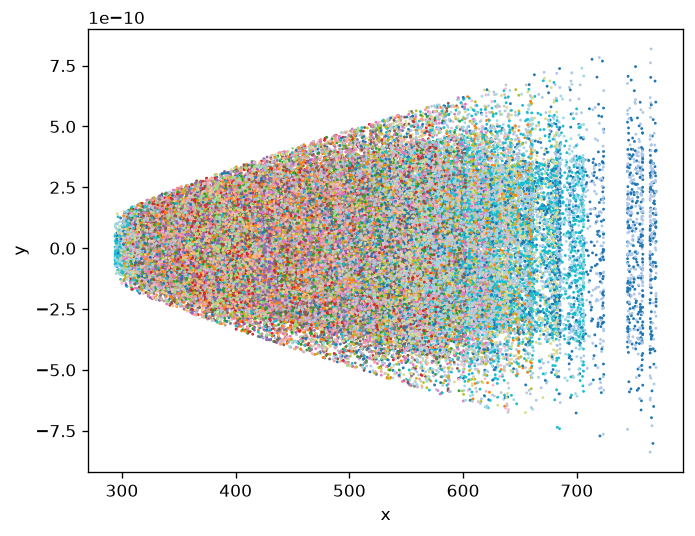

In [3]:
plt.figure(dpi=120)
plt.scatter(surf.x, surf.y, c=surf.idx, s=0.5, cmap="tab20")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

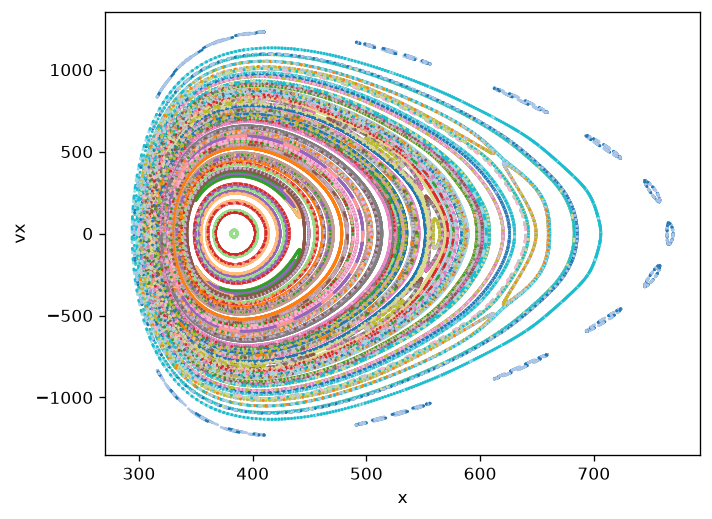

In [4]:
plt.figure(dpi=120)
plt.scatter(surf.x, surf.vx, c=surf.idx, s=0.5, cmap="tab20")
# plt.scatter(surf.x, surf.vx, c="gray", s=0.5)
plt.xlabel("x")
plt.ylabel("vx")
plt.show()

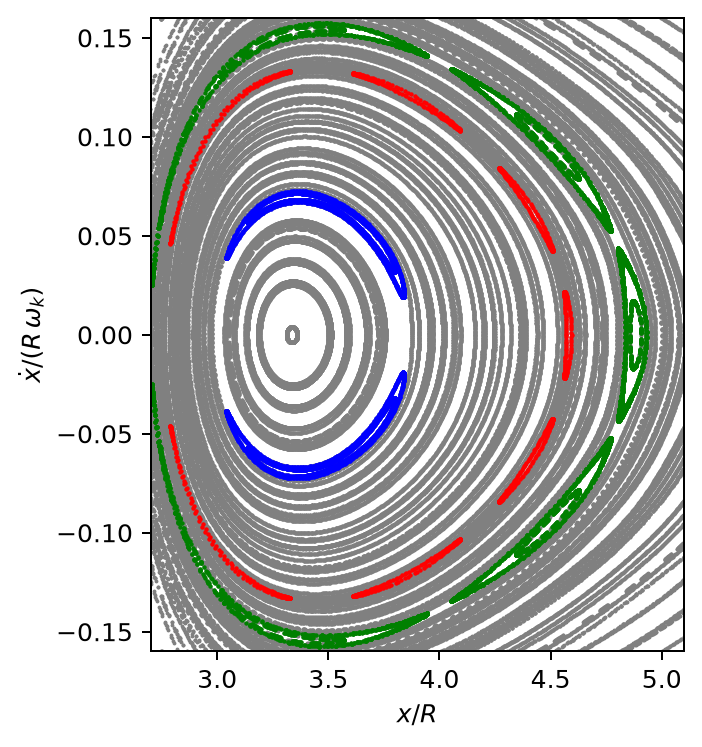

In [ ]:
R0 = 115
wk = 4.542973133885822E+01
plt.figure(dpi=180, figsize=(4,4.25))
plt.scatter(surf.x/R0, surf.vx/(R0*wk), c="gray", s=0.3)
si = surf[surf.idx.isin([93, 103, 120, 128, 134])]
plt.scatter(si.x/R0, si.vx/(R0*wk), c="green", s=0.6)
si = surf[surf.idx == 94]
plt.scatter(si.x/R0, si.vx/(R0*wk), c="red", s=0.6)
si = surf[surf.idx.isin([31,74])]
plt.scatter(si.x/R0, si.vx/(R0*wk), c="blue", s=0.6)
plt.xlabel("$x/R$")
plt.ylabel("$\\dot{x}/(R\\,\\omega_k)$")
plt.xlim(2.7, 5.1)
plt.ylim(-0.16, 0.16)
plt.tight_layout()
plt.show()

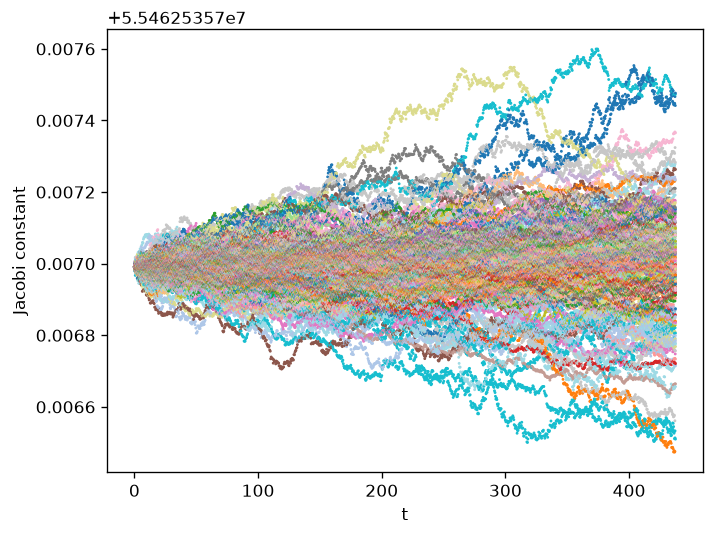

In [6]:
plt.figure(dpi=120)
plt.scatter(surf.t, surf.CJ, c=surf.idx, s=0.5, cmap="tab20")
plt.xlabel("t")
plt.ylabel("Jacobi constant")
plt.show()

In [7]:
surf_inertial = rd.read_surface(
    surface_name="surface.out",
    work_dir="../",
    omega_rotation=21.5423471626332  # Used for this example
)
surf_elem = rd.surface_to_elements(
    surf_inertial,
    msum=6.3e18  # Used for this example
    )
surf_elem

,a,e,i,M,omega,Omega
0,527.636910,0.450222,0.0,6.014819e+00,0.747366,0.0
1,463.442508,0.349608,0.0,5.998111e+00,0.611183,0.0
2,444.741447,0.309816,0.0,6.025621e+00,0.503865,0.0
3,422.957134,0.252288,0.0,3.523338e-08,6.283185,0.0
4,432.347952,0.278979,0.0,1.989337e-01,5.919245,0.0
...,...,...,...,...,...,...
178615,432.416972,0.279178,0.0,5.270080e-02,6.185857,0.0
178616,412.911016,0.218958,0.0,2.103936e+00,3.854033,0.0
178617,461.183784,0.344996,0.0,1.178027e+00,4.405751,0.0
178618,432.223995,0.278622,0.0,5.938757e+00,0.618187,0.0


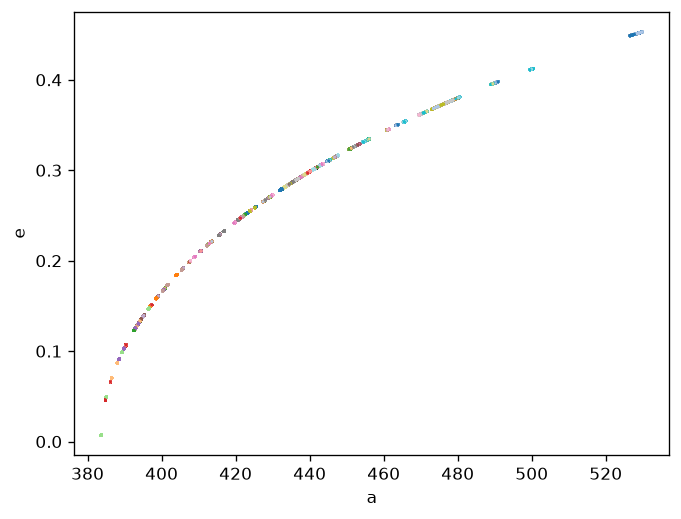

In [8]:
plt.figure(dpi=120)
plt.scatter(surf_elem.a, surf_elem.e, c=surf.idx, s=0.5, cmap="tab20")
plt.xlabel("a")
plt.ylabel("e")
plt.show()